# B6 – Phân tích khám phá dữ liệu (EDA)
**Giai đoạn C – Phân tích & Khai phá** · Phương pháp: [`B06_PHAN_TICH_KHAM_PHA_EDA.md`](../QUY_TRINH_DU_AN/GIAI_DOAN_C_PHAN_TICH_KHAI_PHA/B06_PHAN_TICH_KHAM_PHA_EDA.md)

Notebook này là phần 2 của `01_data_cleaning_eda`. Phần 1 (kiểm tra chất lượng và làm sạch) đã được đóng gói thành script:
* B3 – kiểm tra chất lượng: `python -m src.etl.validate` → [`reports/data_quality_report.md`](../reports/data_quality_report.md)
* B4 – làm sạch: `python -m src.etl.clean` → [`reports/cleaning_log.md`](../reports/cleaning_log.md)

**Dữ liệu:** đọc từ kho Polyglot (PostgreSQL + MongoDB) bằng `load_analytic_table()` của B5.
**Quy ước:** mọi tỷ lệ bỏ học tính trên **tập có nhãn** (`Censored = 0`), vì nhãn của các dòng bị cắt chưa được xác nhận.
Biểu đồ được lưu vào `reports/figures/eda_*.png` để dùng trong báo cáo.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lifelines import KaplanMeierFitter

from src.etl.load import load_analytic_table

sns.set_theme(style="whitegrid", font_scale=0.95)
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
T = "Target_Dropout_Next_Sem"
C0, C1 = "#4C72B0", "#C44E52"  # ở lại / bỏ học

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=110, bbox_inches="tight")

df = load_analytic_table()
lab = df[df["Censored"] == 0].copy()
print(f"Toàn bộ: {len(df):,} dòng, {df['Student_ID'].nunique():,} sinh viên")
print(f"Tập có nhãn (Censored = 0): {len(lab):,} dòng, {lab['Student_ID'].nunique():,} sinh viên")

Toàn bộ: 79,239 dòng, 20,000 sinh viên
Tập có nhãn (Censored = 0): 68,124 dòng, 17,928 sinh viên


## 1. Mất cân bằng nhãn và tỷ lệ bỏ học theo học kỳ

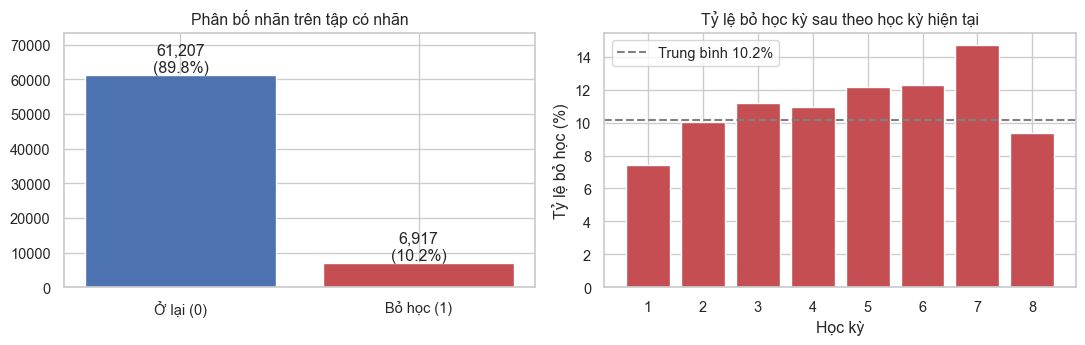

,ty_le,so_dong
Semester,,
1,7.4,17928
2,10.0,14704
3,11.2,11528
4,11.0,8655
5,12.2,6325
6,12.3,4265
7,14.7,2547
8,9.4,2172


In [2]:
rate_sem = lab.groupby("Semester")[T].agg(ty_le="mean", so_dong="size")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts = lab[T].value_counts().sort_index()
axes[0].bar(["Ở lại (0)", "Bỏ học (1)"], counts.values, color=[C0, C1])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
axes[0].set_title("Phân bố nhãn trên tập có nhãn")
axes[0].set_ylim(0, counts.max() * 1.2)
axes[1].bar(rate_sem.index, rate_sem["ty_le"] * 100, color=C1)
axes[1].axhline(lab[T].mean() * 100, color="gray", ls="--", label=f"Trung bình {lab[T].mean():.1%}")
axes[1].set_xlabel("Học kỳ"); axes[1].set_ylabel("Tỷ lệ bỏ học (%)")
axes[1].set_title("Tỷ lệ bỏ học kỳ sau theo học kỳ hiện tại"); axes[1].legend()
save(fig, "eda_label_by_semester.png"); plt.show()
rate_sem.assign(ty_le=lambda t: (t["ty_le"] * 100).round(1))

**Nhận xét:**
* Lớp bỏ học chiếm **10,2%** tập có nhãn (6.917 / 68.124 dòng) → mất cân bằng, cần PR-AUC và trọng số lớp (B10).
* Kỳ 1 có tỷ lệ thấp nhất (**7,4%**), tăng dần tới **14,7%** ở kỳ 7; kỳ 8 giảm còn 9,4% (gần tốt nghiệp). Rủi ro **không đều theo thời gian**, nên `Semester` là đặc trưng cần giữ.

## 2. Số kỳ được theo dõi của mỗi sinh viên

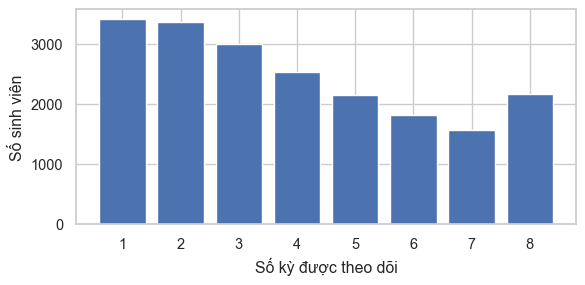

{1: 3404, 2: 3365, 3: 2992, 4: 2534, 5: 2151, 6: 1812, 7: 1570, 8: 2172} | trung bình 3.96 kỳ


In [3]:
per_student = df.groupby("Student_ID")["Semester"].max().value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(per_student.index, per_student.values, color=C0)
ax.set_xlabel("Số kỳ được theo dõi"); ax.set_ylabel("Số sinh viên")
save(fig, "eda_semesters_per_student.png"); plt.show()
print(per_student.to_dict(), "| trung bình", round(df.groupby("Student_ID").size().mean(), 2), "kỳ")

**Nhận xét:** 3.404 sinh viên chỉ có 1 kỳ dữ liệu, trung bình 3,96 kỳ. Với những dòng đầu tiên, đặc trưng Lag/Delta ở B7 sẽ trống, nên cần cờ `Is_First_Semester`.

## 3. Tỷ lệ bỏ học theo nhóm

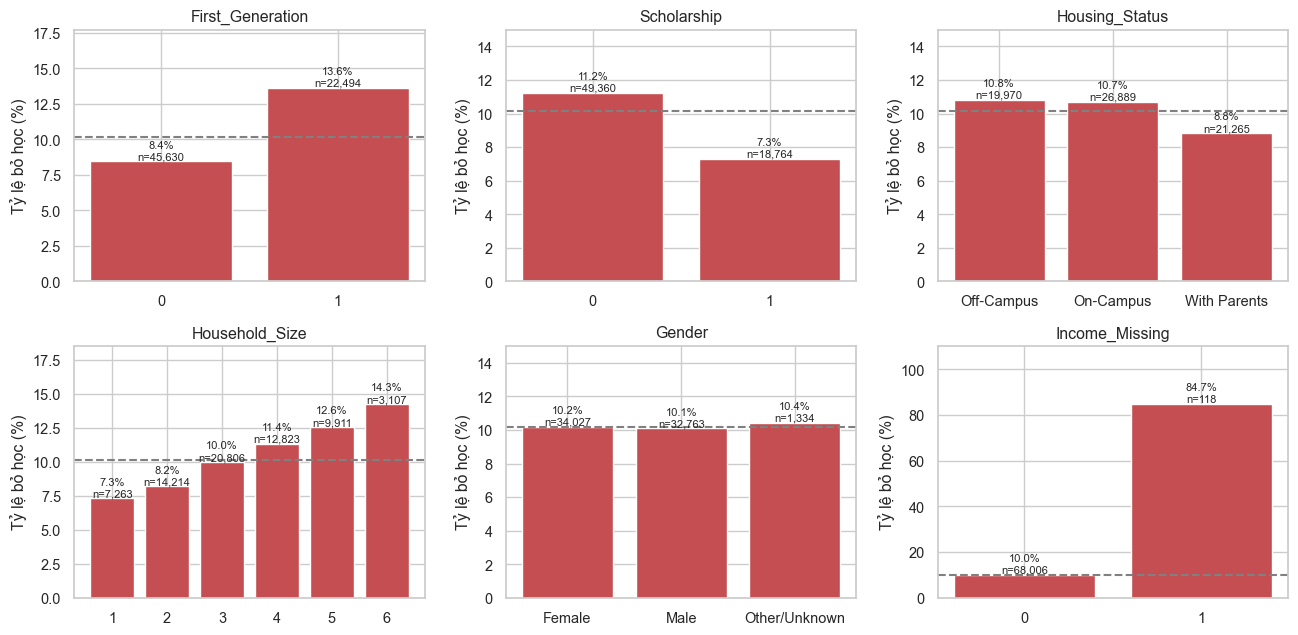

ty_le  so_dong
First_Generation 0                8.4    45630
                 1               13.6    22494
Scholarship      0               11.2    49360
                 1                7.3    18764
Housing_Status   Off-Campus      10.8    19970
                 On-Campus       10.7    26889
                 With Parents     8.8    21265
Household_Size   1                7.3     7263
                 2                8.2    14214
                 3               10.0    20806
                 4               11.4    12823
                 5               12.6     9911
                 6               14.3     3107
Gender           Female          10.2    34027
                 Male            10.1    32763
                 Other/Unknown   10.4     1334
Income_Missing   0               10.0    68006
                 1               84.7      118

In [4]:
groups = ["First_Generation", "Scholarship", "Housing_Status", "Household_Size", "Gender", "Income_Missing"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
tables = {}
for ax, col in zip(axes.flat, groups):
    t = lab.groupby(col)[T].agg(ty_le="mean", so_dong="size")
    tables[col] = t
    ax.bar(t.index.astype(str), t["ty_le"] * 100, color=C1)
    ax.axhline(lab[T].mean() * 100, color="gray", ls="--")
    for i, (r, n) in enumerate(zip(t["ty_le"], t["so_dong"])):
        ax.text(i, r * 100, f"{r:.1%}\nn={n:,}", ha="center", va="bottom", fontsize=8)
    ax.set_title(col); ax.set_ylabel("Tỷ lệ bỏ học (%)")
    ax.set_ylim(0, max(t["ty_le"].max() * 100 * 1.3, 15))
save(fig, "eda_group_rates.png"); plt.show()
pd.concat({k: v.assign(ty_le=lambda t: (t["ty_le"] * 100).round(1)) for k, v in tables.items()})

**Nhận xét:**
* **Thế hệ đầu học đại học:** 13,6% so với 8,4%, nguy cơ cao hơn khoảng 1,6 lần.
* **Học bổng:** 7,3% so với 11,2%; có học bổng thì tỷ lệ bỏ học thấp hơn.
* **Quy mô hộ gia đình:** tăng đều từ 7,3% (1 người) lên 14,3% (6 người).
* **Nơi ở:** sống cùng bố mẹ thấp hơn (8,8%) so với ở ký túc xá / thuê ngoài (~10,8%).
* **Giới tính:** gần như không khác biệt (10,1 – 10,4%). Đặc trưng này ít giá trị, và nên kiểm tra **công bằng** ở B12 thay vì kỳ vọng nó giúp dự báo.
* **Không khai báo thu nhập (`Income_Missing = 1`):** tỷ lệ bỏ học **84,7%**, nhưng chỉ có **118 dòng**. Đây là tín hiệu mạnh của dữ liệu thiếu **không ngẫu nhiên (MNAR)**, xác nhận quyết định giữ cờ `Income_Missing` ở B4. Vì nhóm rất nhỏ, ở B13 cần kiểm tra mô hình không phụ thuộc quá mức vào cờ này.

## 4. Phân phối các biến chính theo nhãn

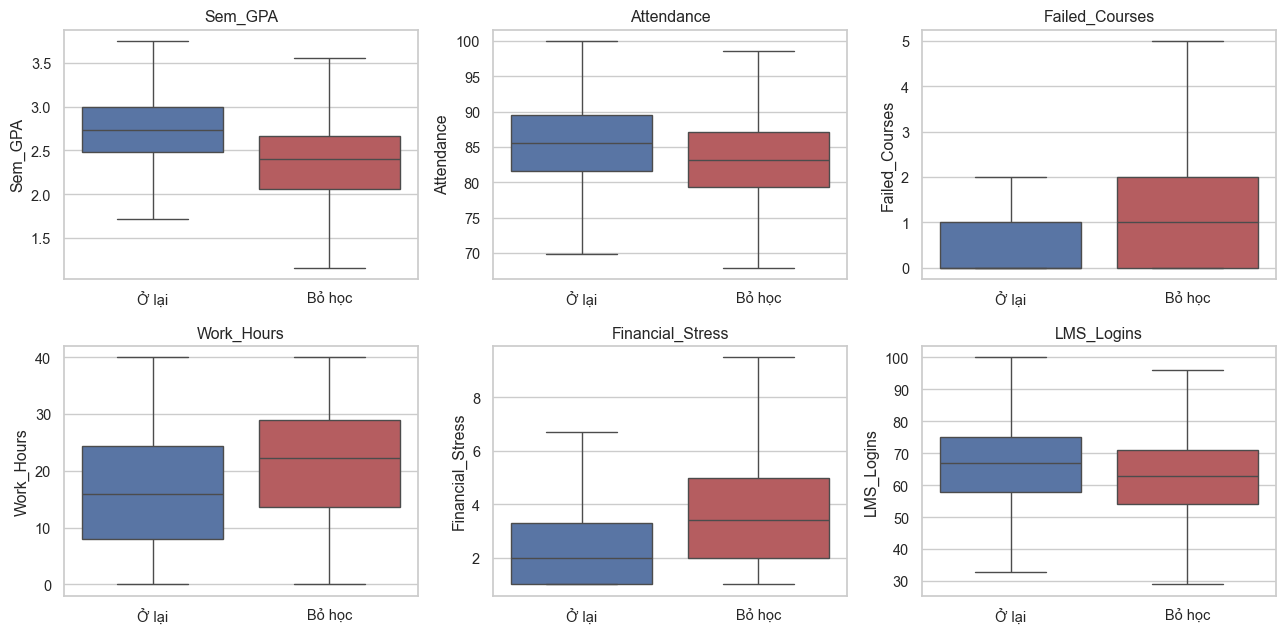

Target_Dropout_Next_Sem             0             1
Sem_GPA          mean        2.731181      2.345288
                 median          2.73           2.4
Attendance       mean       85.477877     83.305263
                 median          85.5          83.2
Failed_Courses   mean        0.596762      1.201677
                 median           0.0           1.0
Work_Hours       mean       16.532663     21.289562
                 median          16.0          22.2
Financial_Stress mean        2.460233      3.872372
                 median           2.0           3.4
LMS_Logins       mean       66.765209       62.8286
                 median          67.0          63.0
Advising_Visits  mean         0.46212      0.627295
                 median           0.0           0.0
Course_Load      mean       14.832519     15.505277
                 median          15.0          15.0
Family_Income    mean    62630.342055  49507.261259
                 median       53000.0       41000.0

In [5]:
cols = ["Sem_GPA", "Attendance", "Failed_Courses", "Work_Hours", "Financial_Stress", "LMS_Logins"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(data=lab, x=T, y=col, hue=T, palette=[C0, C1], legend=False, ax=ax, showfliers=False)
    ax.set_xticks([0, 1], ["Ở lại", "Bỏ học"]); ax.set_xlabel("")
    ax.set_title(col)
save(fig, "eda_distributions.png"); plt.show()
lab.groupby(T)[cols + ["Advising_Visits", "Course_Load", "Family_Income"]].agg(["mean", "median"]).T.round(2)

**Nhận xét** (trung bình nhóm ở lại so với nhóm bỏ học):
* **Học tập:** GPA 2,73 so với 2,35; số môn trượt 0,60 so với 1,20 (gấp đôi).
* **Tài chính:** áp lực tài chính 2,46 so với 3,87; giờ làm thêm 16,5 so với 21,3 giờ/tuần; thu nhập gia đình 62.600 so với 49.500.
* **Tương tác:** chuyên cần 85,5% so với 83,3%; đăng nhập LMS 66,8 so với 62,8. Khác biệt có nhưng nhỏ hơn nhóm học tập và tài chính.
* **Gặp cố vấn:** 0,46 so với 0,63 lần. Nhóm bỏ học gặp cố vấn **nhiều hơn**. Đây là ví dụ của **tương quan ≠ nhân quả** (nhân quả ngược): sinh viên đang gặp khó khăn mới tìm đến cố vấn, chứ không phải gặp cố vấn gây ra bỏ học.

## 5. Ma trận tương quan Spearman

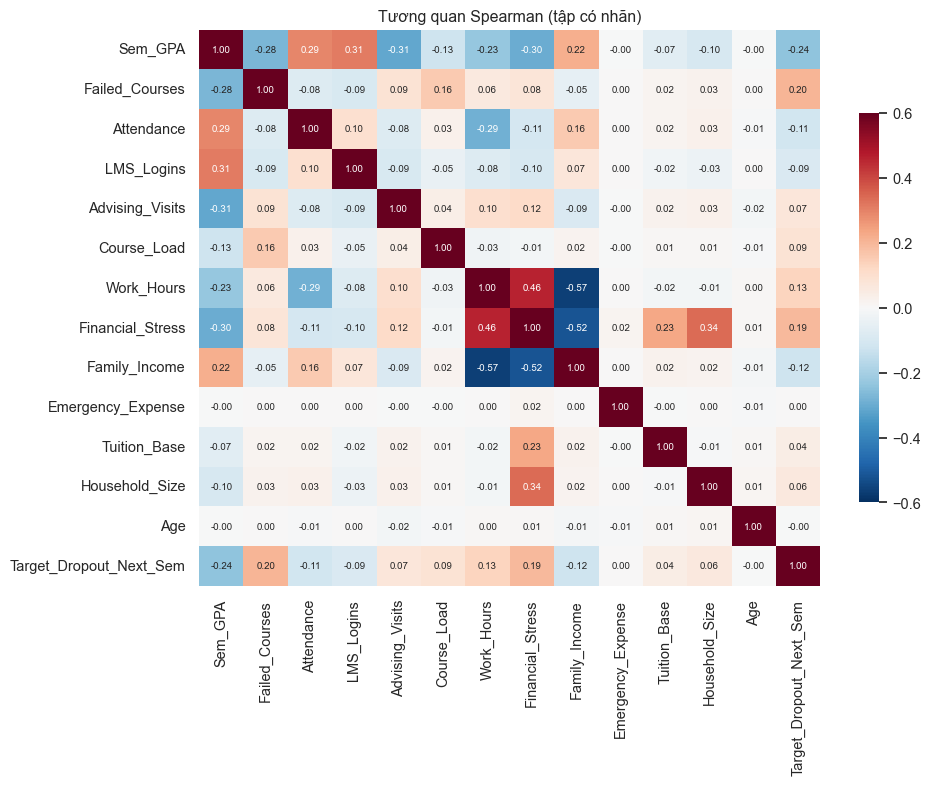

Sem_GPA             -0.243
Family_Income       -0.123
Attendance          -0.114
LMS_Logins          -0.089
Age                 -0.000
Emergency_Expense    0.001
Tuition_Base         0.045
Household_Size       0.062
Advising_Visits      0.072
Course_Load          0.088
Work_Hours           0.134
Financial_Stress     0.194
Failed_Courses       0.203
Name: Target_Dropout_Next_Sem, dtype: float64

In [6]:
num = ["Sem_GPA", "Failed_Courses", "Attendance", "LMS_Logins", "Advising_Visits", "Course_Load",
       "Work_Hours", "Financial_Stress", "Family_Income", "Emergency_Expense", "Tuition_Base",
       "Household_Size", "Age", T]
corr = lab[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Tương quan Spearman (tập có nhãn)")
save(fig, "eda_correlation.png"); plt.show()
corr[T].drop(T).sort_values().round(3)

**Nhận xét:**
* Tương quan với nhãn mạnh nhất: `Sem_GPA` (−0,24), `Failed_Courses` (+0,20), `Financial_Stress` (+0,19), `Work_Hours` (+0,13), `Family_Income` (−0,12), `Attendance` (−0,11).
* Không biến đơn lẻ nào có |ρ| > 0,25, nên dự báo cần **kết hợp nhiều yếu tố** (phù hợp mô hình cây ở B11).
* `Age`, `Emergency_Expense` gần như không tương quan với nhãn ở dạng thô. `Emergency_Expense` có thể có ích hơn ở dạng tích lũy hoặc cờ `Has_Emergency` (B7).
* **Đa cộng tuyến vừa phải** giữa nhóm tài chính: `Family_Income` – `Work_Hours` (−0,57), `Family_Income` – `Financial_Stress` (−0,52). Ảnh hưởng tới diễn giải hệ số LogReg và cách SHAP chia đóng góp (B13), không ảnh hưởng nhiều tới mô hình cây.

## 6. Quỹ đạo theo thời gian: dữ liệu theo chiều dọc có đáng giá không?

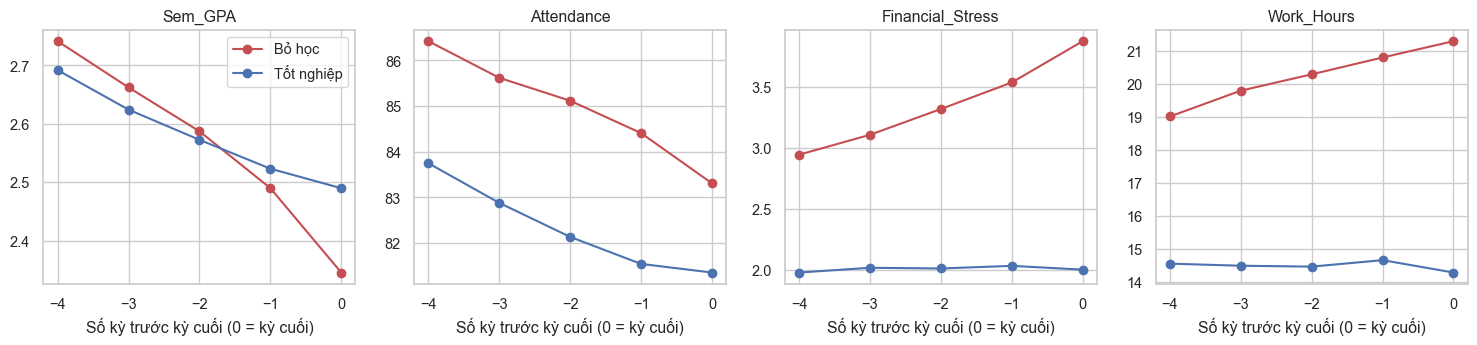

Sem_GPA  Attendance  Financial_Stress  Work_Hours
ket_cuc    k                                                   
Bỏ học     0     2.35       83.31              3.87       21.29
           1     2.49       84.41              3.53       20.80
           2     2.59       85.12              3.32       20.29
           3     2.66       85.62              3.11       19.79
           4     2.74       86.42              2.94       19.01
Tốt nghiệp 0     2.49       81.35              2.00       14.29
           1     2.52       81.54              2.03       14.66
           2     2.57       82.13              2.01       14.46
           3     2.62       82.88              2.02       14.49
           4     2.69       83.75              1.98       14.56

In [7]:
d = df.sort_values(["Student_ID", "Semester"]).copy()
d["k"] = d.groupby("Student_ID")["Semester"].transform("max") - d["Semester"]  # số kỳ trước kỳ cuối
outcome = d.groupby("Student_ID")["End_of_Semester_Status"].last()
d["ket_cuc"] = d["Student_ID"].map(outcome).map({"Dropped_Out": "Bỏ học", "Graduated": "Tốt nghiệp"})
traj = d[d["ket_cuc"].notna() & (d["k"] <= 4)]
metrics = ["Sem_GPA", "Attendance", "Financial_Stress", "Work_Hours"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, m in zip(axes, metrics):
    t = traj.groupby(["ket_cuc", "k"])[m].mean().unstack(0)
    for col, color in (("Bỏ học", C1), ("Tốt nghiệp", C0)):
        ax.plot(-t.index, t[col], marker="o", color=color, label=col)
    ax.set_title(m); ax.set_xlabel("Số kỳ trước kỳ cuối (0 = kỳ cuối)")
axes[0].legend()
save(fig, "eda_trajectory.png"); plt.show()
traj.groupby(["ket_cuc", "k"])[metrics].mean().round(2)

**Nhận xét** (căn theo kỳ cuối cùng của mỗi sinh viên):
* **Sinh viên bỏ học** sa sút rõ trong 4 kỳ trước khi bỏ: GPA **2,74 → 2,35**, áp lực tài chính **2,94 → 3,87**, giờ làm thêm 19,0 → 21,3, chuyên cần 86,4 → 83,3, LMS 66,8 → 62,8.
* **Sinh viên tốt nghiệp:** GPA cũng giảm nhẹ (2,62 → 2,49) nhưng **áp lực tài chính gần như phẳng (~2,0)**. Điểm khác biệt nằm ở **hướng thay đổi** của tài chính và tốc độ sụt điểm, không chỉ ở giá trị hiện tại.
* **Lưu ý khi đọc biểu đồ:** sinh viên tốt nghiệp được so ở các kỳ muộn (5 – 8), nên **mức** của một số biến bị nhiễu bởi học kỳ. Ví dụ chuyên cần của nhóm tốt nghiệp (83,8 → 81,4) còn thấp hơn nhóm bỏ học. Thông tin đáng tin là **chiều hướng**: áp lực tài chính và giờ làm thêm **tăng dần** ở nhóm bỏ học nhưng **đi ngang** ở nhóm tốt nghiệp (giờ làm thêm ~14,5).
* ⇒ Đây là bằng chứng chính cho giá trị của **dữ liệu theo chiều dọc**: các đặc trưng Delta / Rolling / Slope ở B7 mã hóa đúng hiện tượng này.

## 7. Kiểm tra trước giả thuyết đặc trưng cho B7

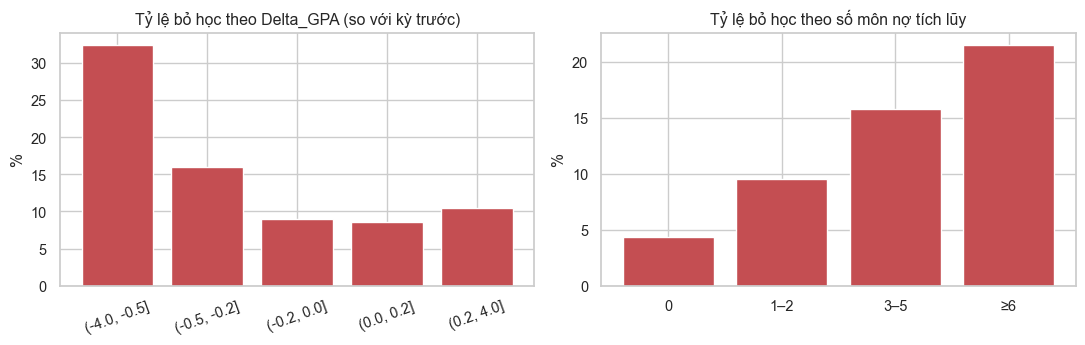

,ty_le,so_dong
Delta_GPA,,
"(-4.0, -0.5]",32.5,1639
"(-0.5, -0.2]",16.0,10407
"(-0.2, 0.0]",9.0,28263
"(0.0, 0.2]",8.6,9589
"(0.2, 4.0]",10.4,298


,ty_le,so_dong
Cum_Failed,,
0,4.4,18683
1–2,9.5,30324
3–5,15.8,15650
≥6,21.5,3467


In [8]:
d["Delta_GPA"] = d.groupby("Student_ID")["Sem_GPA"].diff()
d["Cum_Failed"] = d.groupby("Student_ID")["Failed_Courses"].cumsum()
dl = d[d["Censored"] == 0]
by_delta = dl.dropna(subset=["Delta_GPA"]).groupby(
    pd.cut(dl["Delta_GPA"], [-4, -0.5, -0.2, 0, 0.2, 4]), observed=True)[T].agg(ty_le="mean", so_dong="size")
by_cum = dl.groupby(pd.cut(dl["Cum_Failed"], [-1, 0, 2, 5, 100], labels=["0", "1–2", "3–5", "≥6"]),
                    observed=True)[T].agg(ty_le="mean", so_dong="size")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(by_delta.index.astype(str), by_delta["ty_le"] * 100, color=C1)
axes[0].set_title("Tỷ lệ bỏ học theo Delta_GPA (so với kỳ trước)"); axes[0].set_ylabel("%")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(by_cum.index.astype(str), by_cum["ty_le"] * 100, color=C1)
axes[1].set_title("Tỷ lệ bỏ học theo số môn nợ tích lũy"); axes[1].set_ylabel("%")
save(fig, "eda_delta_cumulative.png"); plt.show()
display(by_delta.assign(ty_le=lambda t: (t["ty_le"] * 100).round(1)))
by_cum.assign(ty_le=lambda t: (t["ty_le"] * 100).round(1))

**Nhận xét:**
* GPA **tụt ≥ 0,5** so với kỳ trước: tỷ lệ bỏ học **32,5%**, so với ~9% khi GPA ổn định (gấp ~3,5 lần).
* Số môn nợ **tích lũy** tăng đều: 4,4% (0 môn) → 9,5% → 15,8% → **21,5%** (≥ 6 môn).
* ⇒ Hai đặc trưng `Delta_GPA` và `Cum_Failed_Courses` của B7 có tín hiệu rõ ngay từ EDA.

## 8. Đường cong sống sót Kaplan–Meier

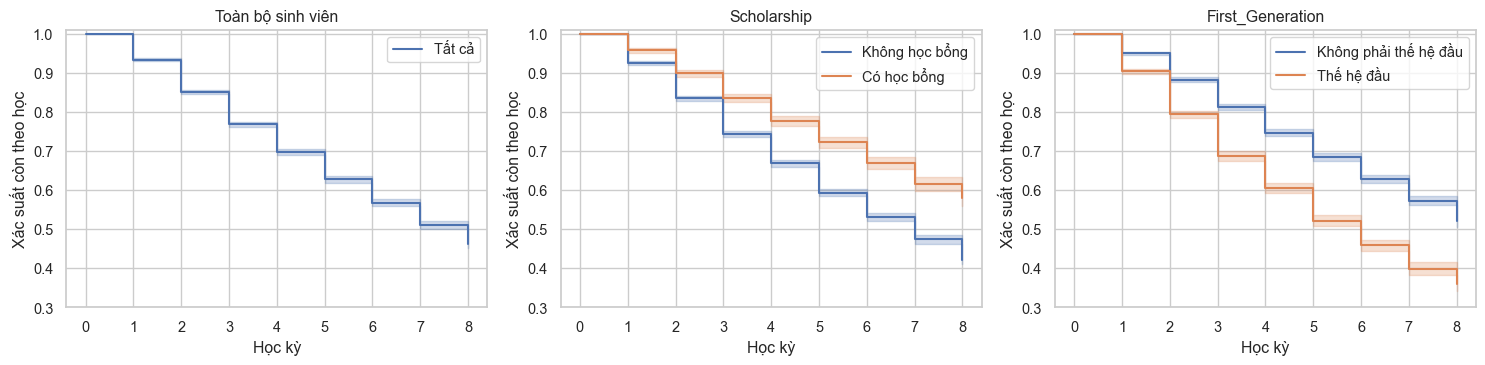

,Tất cả,Không học bổng,Có học bổng,Không phải thế hệ đầu,Thế hệ đầu
timeline,,,,,
0.0,1.000,1.000,1.000,1.000,1.000
1.0,0.933,0.925,0.957,0.950,0.903
2.0,0.851,0.834,0.898,0.882,0.793
3.0,0.768,0.744,0.835,0.812,0.687
4.0,0.696,0.668,0.776,0.747,0.604
5.0,0.627,0.593,0.722,0.684,0.522
6.0,0.568,0.532,0.669,0.628,0.458
7.0,0.511,0.474,0.616,0.572,0.399
8.0,0.463,0.422,0.579,0.520,0.359


In [9]:
students = df.sort_values("Semester").groupby("Student_ID").agg(
    duration=("Semester", "max"), status=("End_of_Semester_Status", "last"),
    Scholarship=("Scholarship", "first"), First_Generation=("First_Generation", "first"))
students["event"] = (students["status"] == "Dropped_Out").astype(int)  # tốt nghiệp / bị cắt = censored
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
kmf = KaplanMeierFitter()
kmf.fit(students["duration"], students["event"], label="Tất cả").plot_survival_function(ax=axes[0])
axes[0].set_title("Toàn bộ sinh viên")
summary = {"Tất cả": kmf.survival_function_.iloc[:, 0]}
for ax, col, names in ((axes[1], "Scholarship", {0: "Không học bổng", 1: "Có học bổng"}),
                       (axes[2], "First_Generation", {0: "Không phải thế hệ đầu", 1: "Thế hệ đầu"})):
    for value, name in names.items():
        g = students[students[col] == value]
        kmf.fit(g["duration"], g["event"], label=name).plot_survival_function(ax=ax)
        summary[name] = kmf.survival_function_.iloc[:, 0]
    ax.set_title(col)
for ax in axes:
    ax.set_xlabel("Học kỳ"); ax.set_ylabel("Xác suất còn theo học"); ax.set_ylim(0.3, 1.01)
save(fig, "eda_kaplan_meier.png"); plt.show()
pd.DataFrame(summary).round(3)

**Nhận xét:**
* Kaplan–Meier **dùng đúng thông tin của sinh viên bị cắt** (họ vẫn được tính "còn theo học" cho tới kỳ cuối được quan sát), khác với cách chỉ đếm tỷ lệ bỏ học.
* Xác suất còn theo học (chưa bỏ học) sau 8 kỳ: **46,3%** toàn bộ. Có học bổng **57,9%** so với không học bổng **42,2%**; không phải thế hệ đầu **52,0%** so với thế hệ đầu **35,9%**. Các đường tách nhau ngay từ kỳ 1 và khoảng cách lớn dần, khớp với mục 3.
* Đây là gợi ý cho hướng phát triển **Survival Analysis** (B17).

## 9. Tổng hợp insight và giả thuyết đặc trưng cho B7

| # | Insight | Hệ quả cho các bước sau |
|:---:|---|---|
| 1 | Lớp bỏ học 10,2%, tăng từ 7,4% (kỳ 1) tới 14,7% (kỳ 7) | PR-AUC + trọng số lớp (B10–B12); giữ `Semester`, thêm `Is_First_Semester` |
| 2 | Học tập là nhóm mạnh nhất: GPA (ρ = −0,24), môn trượt (+0,20) | `CGPA`, `Cum_Failed_Courses`, `Failed_Ratio` |
| 3 | Tài chính mạnh thứ hai: áp lực 2,46 → 3,87, làm thêm 16,5 → 21,3 giờ, thu nhập thấp hơn | `Financial_Burden_Index`, `Tuition_to_Income`, giữ nguyên `Financial_Stress` |
| 4 | Sinh viên bỏ học sa sút trong 4 kỳ trước khi bỏ; người tốt nghiệp có áp lực tài chính phẳng | `Delta_*`, `*_Roll3`, `GPA_Slope`, `Delta_Stress` |
| 5 | GPA tụt ≥ 0,5: 32,5% bỏ học; nợ tích lũy ≥ 6 môn: 21,5% | Xác nhận `Delta_GPA`, `Cum_Failed_Courses` |
| 6 | Thế hệ đầu 13,6% so với 8,4%; học bổng 7,3% so với 11,2%; hộ đông người rủi ro cao hơn | Giữ các biến nhân khẩu học; kiểm tra công bằng theo `First_Generation` ở B12 |
| 7 | Không khai báo thu nhập: 84,7% bỏ học (118 dòng) | Giữ cờ `Income_Missing`; theo dõi mức phụ thuộc ở SHAP (B13) |
| 8 | Gặp cố vấn nhiều hơn ở nhóm bỏ học (nhân quả ngược) | Giữ làm tín hiệu "đang gặp khó", **không** diễn giải là nguyên nhân |
| 9 | Giới tính, tuổi gần như không khác biệt | Dùng cho kiểm tra công bằng, không kỳ vọng giúp dự báo |
| 10 | Nhóm tài chính tương quan với nhau (|ρ| ≈ 0,5–0,57) | Lưu ý khi đọc hệ số LogReg và SHAP |